# Detecção de Fraude em Cartões de Crédito

Notebook com exploração dos dados, preparação, treinamento, avaliação, ajuste de limiar, reamostragem e explicabilidade com SHAP.


--- 1. EXPLORAR ---
Shape do dataset: (284807, 31)
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.1

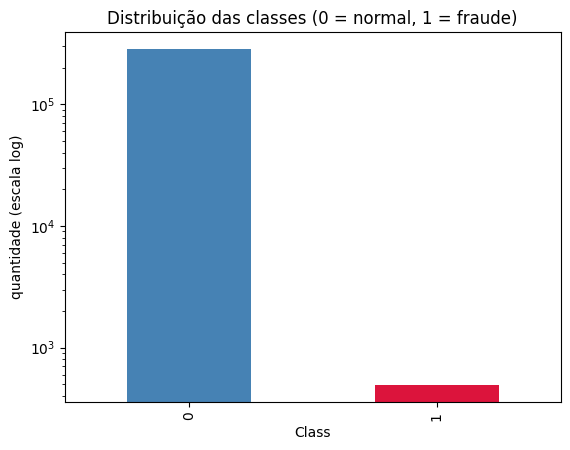


Acurácia do modelo que nunca detecta fraude: 99.8273%
Recall da fraude desse modelo: 0.0000

Estatísticas de valor (Amount) por classe:
          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87

--- 2. PREPARAR ---
treino: 181584 linhas | fraude = 0.1663% (302 casos)
validação: 45396 linhas | fraude = 0.1674% (76 casos)
teste: 56746 linhas | fraude = 0.1674% (95 casos)

--- 3. TREINAR ---
scale_pos_weight: 600.3
treinado: Regressão Logística
treinado: Random Forest
treinado: XGBoost

--- 4. AVALIAR ---

Teste, limiar padrão 0.5:
                     recall_fraude  precisao_fraude  f1_fraude  PR-AUC  \
Regressão Logística         0.8737           0.0509     0.0962  0.6785   
Random Forest               0.7158           0.8831     0.7907  0.7840

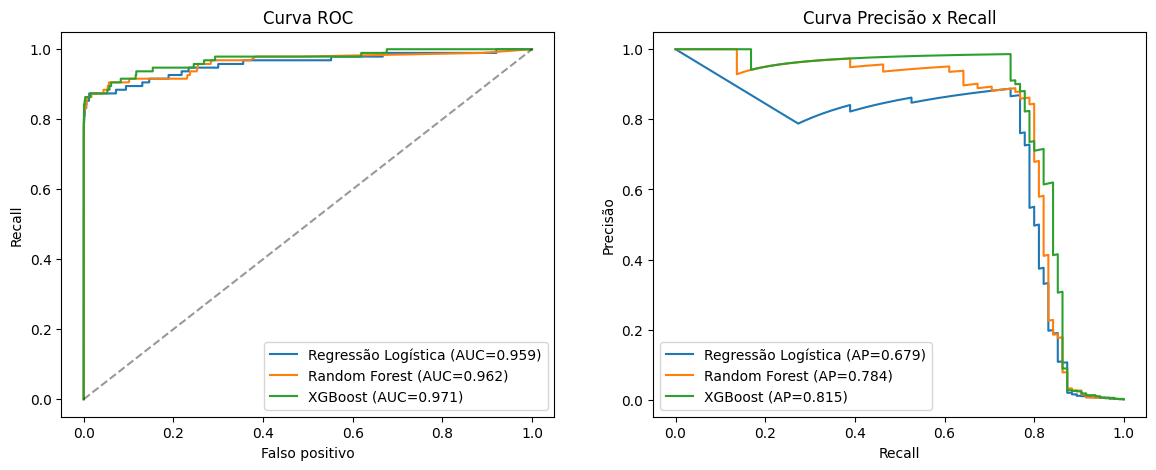


--- Ajuste do Limiar ---

Teste, limiar escolhido na validação:
                     limiar  recall_fraude  precisao_fraude  f1_fraude  \
Regressão Logística  0.9999         0.7684           0.7849     0.7766   
Random Forest        0.4192         0.7368           0.8861     0.8046   
XGBoost              0.9163         0.7474           0.9861     0.8503   

                     PR-AUC  ROC-AUC  
Regressão Logística  0.6785   0.9586  
Random Forest        0.7840   0.9625  
XGBoost              0.8155   0.9709  

Modelo escolhido (maior F1 da fraude no teste): XGBoost | limiar: 0.9163
              precision    recall  f1-score   support

      normal     0.9996    1.0000    0.9998     56651
      fraude     0.9861    0.7474    0.8503        95

    accuracy                         0.9996     56746
   macro avg     0.9928    0.8737    0.9250     56746
weighted avg     0.9996    0.9996    0.9995     56746


Matriz de Confusão:
             prev normal  prev fraude
real normal        566

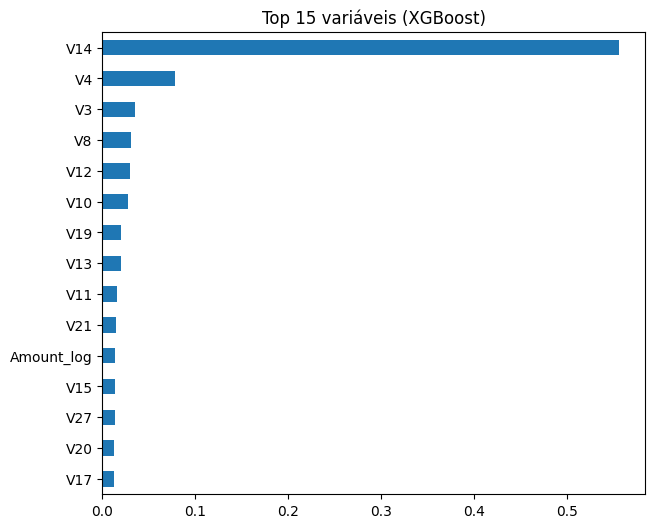


Gerando gráfico SHAP (Beeswarm)...


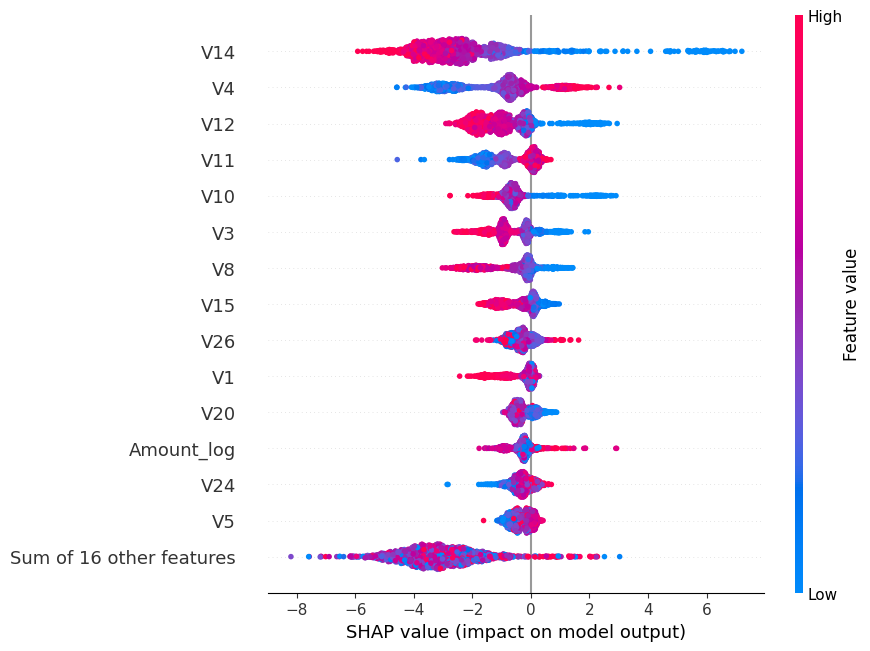


Explicação individual - Probabilidade de fraude: 0.9980 (limiar 0.9163)


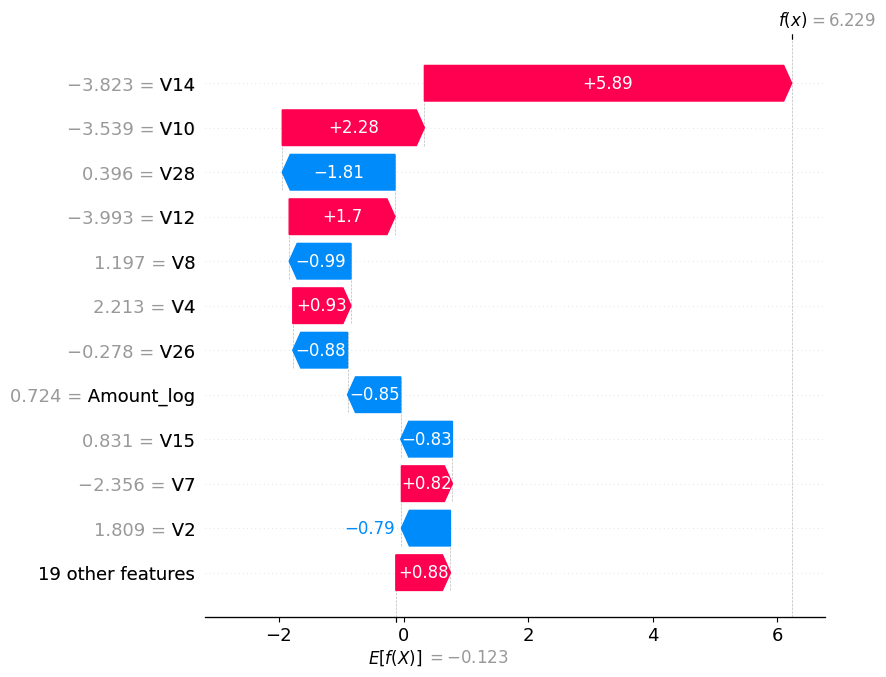

In [1]:
# ==============================================================================
# INSTALAÇÃO DAS BIBLIOTECAS
# ==============================================================================
!pip install -q xgboost shap imbalanced-learn

# ==============================================================================
# IMPORTAÇÕES
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, precision_score,
                             recall_score, f1_score, roc_auc_score, average_precision_score,
                             roc_curve, precision_recall_curve)
from xgboost import XGBClassifier
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

RANDOM_STATE = 42

# ==============================================================================
# 1. EXPLORAR
# ==============================================================================
print("\n--- 1. EXPLORAR ---")
# Link público e estável do dataset (Credit Card Fraud Detection)
DATA_URL = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"

df = pd.read_csv(DATA_URL)
print("Shape do dataset:", df.shape)
print(df.head())

print("\nInformações do dataset:")
df.info()
print("Valores nulos:", df.isnull().sum().sum())
print("Duplicadas:", df.duplicated().sum()).

contagem = df["Class"].value_counts()
proporcao = df["Class"].value_counts(normalize=True) * 100
print("\nDistribuição das classes:")
print(pd.DataFrame({"transações": contagem, "%": proporcao.round(4)}))

contagem.plot(kind="bar", color=["steelblue", "crimson"])
plt.title("Distribuição das classes (0 = normal, 1 = fraude)")
plt.yscale("log")
plt.ylabel("quantidade (escala log)")
plt.show()

acc_ingenuo = (df["Class"] == 0).mean()
print(f"\nAcurácia do modelo que nunca detecta fraude: {acc_ingenuo:.4%}")
print("Recall da fraude desse modelo: 0.0000")

print("\nEstatísticas de valor (Amount) por classe:")
print(df.groupby("Class")["Amount"].describe())


# ==============================================================================
# 2. PREPARAR
# ==============================================================================
print("\n--- 2. PREPARAR ---")
df = df.drop_duplicates().reset_index(drop=True)
df["Amount_log"] = np.log1p(df["Amount"])

X = df.drop(columns=["Class", "Amount"])
y = df["Class"]

# Split treino/teste
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

# Split treino/validação
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, stratify=y_train_full, random_state=RANDOM_STATE)

cols_escala = ["Time", "Amount_log"]
scaler = StandardScaler().fit(X_train[cols_escala])   # ajusta só no treino

for d in (X_train, X_val, X_test):
    d[cols_escala] = scaler.transform(d[cols_escala])

for nome, alvo in [("treino", y_train), ("validação", y_val), ("teste", y_test)]:
    print(f"{nome}: {len(alvo)} linhas | fraude = {alvo.mean():.4%} ({alvo.sum()} casos)")


# ==============================================================================
# 3. TREINAR
# ==============================================================================
print("\n--- 3. TREINAR ---")
peso_pos = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight:", round(peso_pos, 1))

modelos = {
    "Regressão Logística": LogisticRegression(class_weight="balanced", max_iter=1000,
                                              random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=12,
                                            class_weight="balanced_subsample",
                                            n_jobs=-1, random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1,
                             scale_pos_weight=peso_pos, eval_metric="aucpr",
                             tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE),
}

for nome, m in modelos.items():
    m.fit(X_train, y_train)
    print("treinado:", nome)


# ==============================================================================
# 4. AVALIAR
# ==============================================================================
print("\n--- 4. AVALIAR ---")
def metricas(y_true, proba, limiar=0.5):
    pred = (proba >= limiar).astype(int)
    return {
        "recall_fraude": recall_score(y_true, pred),
        "precisao_fraude": precision_score(y_true, pred, zero_division=0),
        "f1_fraude": f1_score(y_true, pred),
        "PR-AUC": average_precision_score(y_true, proba),
        "ROC-AUC": roc_auc_score(y_true, proba),
    }

proba_teste = {n: m.predict_proba(X_test)[:, 1] for n, m in modelos.items()}

tabela = pd.DataFrame({n: metricas(y_test, p) for n, p in proba_teste.items()}).T.round(4)
print("\nTeste, limiar padrão 0.5:")
print(tabela)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for n, p in proba_teste.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=f"{n} (AUC={roc_auc_score(y_test, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    ax[1].plot(rec, prec, label=f"{n} (AP={average_precision_score(y_test, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", alpha=.4)
ax[0].set(title="Curva ROC", xlabel="Falso positivo", ylabel="Recall")
ax[1].set(title="Curva Precisão x Recall", xlabel="Recall", ylabel="Precisão")
ax[0].legend(); ax[1].legend()
plt.show()

# --- AJUSTE DO LIMIAR DE DECISÃO ---
print("\n--- Ajuste do Limiar ---")
RECALL_ALVO = 0.85   # ajuste conforme o custo de deixar fraude passar

def escolher_limiar(y_true, proba, recall_alvo=RECALL_ALVO):
    prec, rec, lim = precision_recall_curve(y_true, proba)
    prec, rec = prec[:-1], rec[:-1]
    ok = rec >= recall_alvo
    if not ok.any():
        return 0.5
    idx = np.argmax(np.where(ok, prec, -1))
    return lim[idx]

limiares, linhas = {}, {}
for n, m in modelos.items():
    proba_val = m.predict_proba(X_val)[:, 1]
    limiares[n] = escolher_limiar(y_val, proba_val)
    linhas[n] = metricas(y_test, proba_teste[n], limiares[n])

tabela_lim = pd.DataFrame(linhas).T.round(4)
tabela_lim.insert(0, "limiar", pd.Series(limiares).round(4))
print("\nTeste, limiar escolhido na validação:")
print(tabela_lim)

melhor = tabela_lim["f1_fraude"].idxmax()
print("\nModelo escolhido (maior F1 da fraude no teste):", melhor, "| limiar:", round(limiares[melhor], 4))

pred_final = (proba_teste[melhor] >= limiares[melhor]).astype(int)
print(classification_report(y_test, pred_final, digits=4, target_names=["normal", "fraude"]))

cm = pd.DataFrame(confusion_matrix(y_test, pred_final),
                  index=["real normal", "real fraude"], columns=["prev normal", "prev fraude"])
print("\nMatriz de Confusão:")
print(cm)

# --- ALTERNATIVA: UNDERSAMPLING E OVERSAMPLING ---
print("\n--- Alternativa: Reamostragem ---")
def treinar_xgb():
    return XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1,
                         eval_metric="aucpr", tree_method="hist",
                         n_jobs=-1, random_state=RANDOM_STATE)

estrategias = {
    "Undersampling": RandomUnderSampler(random_state=RANDOM_STATE),
    "SMOTE (oversampling)": SMOTE(random_state=RANDOM_STATE),
}
res = {}
for nome, amostrador in estrategias.items():
    Xr, yr = amostrador.fit_resample(X_train, y_train)
    m = treinar_xgb().fit(Xr, yr)
    res[nome] = metricas(y_test, m.predict_proba(X_test)[:, 1], 0.5)

res["XGBoost com peso de classes"] = tabela.loc["XGBoost"].to_dict()
print("\nComparação de reamostragem (limiar 0.5):")
print(pd.DataFrame(res).T.round(4))


# ==============================================================================
# 5. EXPLICAR (SHAP)
# ==============================================================================
print("\n--- 5. EXPLICAR ---")
xgb = modelos["XGBoost"]
imp = pd.Series(xgb.feature_importances_, index=X_train.columns).sort_values().tail(15)
imp.plot(kind="barh", figsize=(7, 6), title="Top 15 variáveis (XGBoost)")
plt.show()

# Amostra com todas as fraudes do teste (até 100) + normais
fraudes = X_test[y_test == 1].head(100)
normais = X_test[y_test == 0].sample(min(1900, (y_test == 0).sum()), random_state=RANDOM_STATE)
amostra = pd.concat([fraudes, normais])

explainer = shap.TreeExplainer(xgb)
sv = explainer(amostra)

print("\nGerando gráfico SHAP (Beeswarm)...")
shap.plots.beeswarm(sv, max_display=15)

# Explicação de uma transação individual marcada como fraude
proba_amostra = xgb.predict_proba(amostra)[:, 1]
lim_xgb = limiares["XGBoost"]
idx_fraude = int(np.where(proba_amostra >= lim_xgb)[0][0])
print(f"\nExplicação individual - Probabilidade de fraude: {proba_amostra[idx_fraude]:.4f} (limiar {lim_xgb:.4f})")
shap.plots.waterfall(sv[idx_fraude], max_display=12)